# Seleção nested auditável do propensity — execução completa 2024 (08B)

> **tl;dr.** A seleção nested completa usou os 2.251.570 registros certificados de 2024, 3 folds externos, 3 internos e 5 valores congelados de `C` (48 fits). O menor log-loss interno variou entre `C=0,1`, `C=1` e `C=10`, mas `C=1` permaneceu dentro de 1 EP e passou todos os guardrails nos três folds; portanto, o baseline foi preservado. As predições OOF externas cobrem cada observação exatamente uma vez. Nenhum outcome, efeito causal, AIPW ou CATE participou da seleção.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

raiz = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / 'src').exists()).resolve()
sys.path.insert(0, str(raiz))
assert Path(sys.executable).resolve() == (raiz / '.venv/Scripts/python.exe').resolve(), 'Use a .venv do projeto'

from src.amostra import carregar_exercicio
from src.diagnosticos import COLUNAS_PROPENSITY_PRINCIPAL
from src.selecao_nuisance import BASELINE_C, GRADE_C_PROPENSITY, SEED
from src.visualizacao import configurar_plotly, aplicar_tema_ipt

configurar_plotly()
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pasta_tuning = raiz / 'outputs/temporal/tuning'
resumo = json.loads((pasta_tuning / 'nested_propensity_2024_resumo.json').read_text(encoding='utf-8'))
folds_resultado = pd.read_csv(pasta_tuning / 'nested_propensity_2024_folds.csv')
candidatos = pd.read_csv(pasta_tuning / 'nested_propensity_2024_candidatos.csv')
print('Raiz lógica:', raiz)
print('Status:', resumo['status'])
print('Grade pré-especificada:', GRADE_C_PROPENSITY)

Raiz lógica: C:\GitHub\data-science-projects\projetos\big-data-sinasc-causal-ml
Status: NESTED_PROPENSITY_2024_CONCLUIDO
Grade pré-especificada: (0.01, 0.1, 1.0, 10.0, 100.0)


## 1. Objetivo

Pergunta: **na população analítica completa de 2024, `C=1` permanece dentro da regra de 1 EP, passa os guardrails e produz predições OOF externas estáveis sob seleção nested sem outcome?**

Esta é uma auditoria preditiva do propensity, não uma nova análise causal. Unidade: nascido vivo elegível em 2024. Chave: `contador`. Tratamento: início do pré-natal nos meses 1–3 (`T=1`) versus 4–9 (`T=0`). As sete covariáveis pré-tratamento, a grade, os guardrails, a seed e a regra baseline-first foram congelados antes da execução completa.

In [2]:
dados, x, t, _, provenance = carregar_exercicio(raiz)
assert len(dados) == provenance['n'] == 2_251_570
assert dados.contador.notna().all() and dados.contador.is_unique
assert provenance['datas_nascimento']['n_missing'] == 0
assert list(x.columns) == list(COLUNAS_PROPENSITY_PRINCIPAL)
assert not {'tratamento', 'Y_BAIXO_PESO'}.intersection(x.columns)
assert set(np.unique(t)) == {0, 1}
assert resumo['contexto']['n'] == len(dados)
assert resumo['contexto']['parquet_sha256'] == provenance['parquet_sha256']
assert resumo['auditoria']['cobertura_min'] == resumo['auditoria']['cobertura_max'] == 1

contrato = pd.Series({
    'unidade_analise': 'nascido vivo elegível',
    'chave': provenance['chave'],
    'periodo': '2024',
    'n': len(dados),
    'n_t0': int((t == 0).sum()),
    'n_t1': int((t == 1).sum()),
    'tratamento': provenance['t'],
    'outcome_recebido_pela_api': resumo['auditoria']['usa_outcome'],
    'features_pre_tratamento': ', '.join(x.columns),
    'risco_leakage': 'controlado: tuning interno usa somente treino externo; validação externa é predita uma vez',
}, name='contrato')
display(contrato.to_frame())

,contrato
unidade_analise,nascido vivo elegível
chave,contador
periodo,2024
n,2251570
n_t0,309525
n_t1,1942045
tratamento,MESPRENAT 1-3 versus 4-9
outcome_recebido_pela_api,False
features_pre_tratamento,"IDADEMAE_NUM, ESCOLARIDADE_MAE, RACA_COR_MAE, ..."
risco_leakage,controlado: tuning interno usa somente treino ...


## 2. Modelo certificado atual

O propensity principal é regressão logística L2 com `C=1`, solver `lbfgs`, `max_iter=500`, `tol=1e-5` e seed `20240925`. Idade recebe imputação pela mediana, indicador de ausência e padronização; categóricas recebem imputação pela moda e one-hot encoding com níveis desconhecidos ignorados.

Nesta rodada, a seleção nested usa três folds externos estratificados apenas por tratamento. Dentro de cada treino externo, cinco candidatos são comparados em três folds internos; a configuração escolhida é reajustada no treino externo completo e prediz somente a validação externa. O baseline histórico é lido apenas para comparação preditiva e não é sobrescrito.

In [3]:
inventario = pd.DataFrame([
    ['propensity principal/temporal', 'logística L2', 'sete X congeladas', 'mediana+indicador+escala; moda+one-hot', 'C=1; lbfgs; max_iter=500; tol=1e-5', '3 folds T/Y; temporal 5 folds T', SEED, 'AUC/Brier, overlap, ESS, SMD', 'plano Fase 2', False, False, False, True, 'ESPECIFICACAO_FIXA_DOCUMENTADA'],
    ['outcome m0 C1', 'logística L2 no T=0', 'sete X congeladas', 'igual à logística', 'C=1; lbfgs; max_iter=500; tol=1e-5', '3 folds externos T/Y', SEED, 'AUC/AP/Brier/calibração', 'plano Fase 2', False, True, False, True, 'ESPECIFICACAO_FIXA_DOCUMENTADA'],
    ['outcome m1 C1', 'logística L2 no T=1', 'sete X congeladas', 'igual à logística', 'C=1; lbfgs; max_iter=500; tol=1e-5', '3 folds externos T/Y', SEED, 'AUC/AP/Brier/calibração', 'plano Fase 2', False, True, False, True, 'ESPECIFICACAO_FIXA_DOCUMENTADA'],
    ['outcome m0 C2', 'HGB no T=0', 'sete X congeladas', 'idade direta; categorias ordinais', 'iter=100; folhas=15; min_leaf=100; lr=0,1; L2=1; early stopping', '3 folds externos T/Y', SEED, 'AUC/AP/Brier/calibração', 'plano Fase 2', False, True, False, True, 'ESPECIFICACAO_FIXA_DOCUMENTADA'],
    ['outcome m1 C2', 'HGB no T=1', 'sete X congeladas', 'idade direta; categorias ordinais', 'iter=100; folhas=15; min_leaf=100; lr=0,1; L2=1; early stopping', '3 folds externos T/Y', SEED, 'AUC/AP/Brier/calibração', 'plano Fase 2', False, True, False, True, 'ESPECIFICACAO_FIXA_DOCUMENTADA'],
    ['robustez C3 propensity', 'HGB', 'sete X congeladas', 'idade direta; categorias ordinais', 'mesma especificação HGB', '3 folds externos T/Y', SEED, 'AUC/Brier + suporte/balanço', 'robustez Fase 3', False, True, False, True, 'SELECAO_DE_MODELO_SEM_TUNING'],
    ['CATE principal', 'HGB regressor', 'sete X congeladas + pseudo-outcome', 'idade direta; categorias ordinais', 'iter=100; folhas=7; min_leaf=2000; lr=0,1; L2=1', '3 partições municipais A/B/C', SEED, 'calibração/heterogeneidade', 'Fase 4', False, True, False, True, 'ESPECIFICACAO_FIXA_DOCUMENTADA'],
    ['CATE alternativo', 'Ridge', 'sete X congeladas + pseudo-outcome', 'one-hot esparso', 'alpha=10; solver=lsqr; tol=1e-6', 'mesmas partições A/B/C', SEED, 'calibração/heterogeneidade', 'Fase 4', False, True, False, True, 'SELECAO_DE_MODELO_SEM_TUNING'],
], columns=['papel', 'algoritmo', 'features', 'preprocessing', 'hiperparametros', 'folds', 'seed', 'metricas', 'origem', 'tuning', 'comparacao', 'selecao_holdout_cv', 'congelado', 'classificacao'])
display(inventario)

,papel,algoritmo,features,preprocessing,hiperparametros,folds,seed,metricas,origem,tuning,comparacao,selecao_holdout_cv,congelado,classificacao
0,propensity principal/temporal,logística L2,sete X congeladas,mediana+indicador+escala; moda+one-hot,C=1; lbfgs; max_iter=500; tol=1e-5,3 folds T/Y; temporal 5 folds T,20240925,"AUC/Brier, overlap, ESS, SMD",plano Fase 2,False,False,False,True,ESPECIFICACAO_FIXA_DOCUMENTADA
1,outcome m0 C1,logística L2 no T=0,sete X congeladas,igual à logística,C=1; lbfgs; max_iter=500; tol=1e-5,3 folds externos T/Y,20240925,AUC/AP/Brier/calibração,plano Fase 2,False,True,False,True,ESPECIFICACAO_FIXA_DOCUMENTADA
2,outcome m1 C1,logística L2 no T=1,sete X congeladas,igual à logística,C=1; lbfgs; max_iter=500; tol=1e-5,3 folds externos T/Y,20240925,AUC/AP/Brier/calibração,plano Fase 2,False,True,False,True,ESPECIFICACAO_FIXA_DOCUMENTADA
3,outcome m0 C2,HGB no T=0,sete X congeladas,idade direta; categorias ordinais,"iter=100; folhas=15; min_leaf=100; lr=0,1; L2=...",3 folds externos T/Y,20240925,AUC/AP/Brier/calibração,plano Fase 2,False,True,False,True,ESPECIFICACAO_FIXA_DOCUMENTADA
4,outcome m1 C2,HGB no T=1,sete X congeladas,idade direta; categorias ordinais,"iter=100; folhas=15; min_leaf=100; lr=0,1; L2=...",3 folds externos T/Y,20240925,AUC/AP/Brier/calibração,plano Fase 2,False,True,False,True,ESPECIFICACAO_FIXA_DOCUMENTADA
5,robustez C3 propensity,HGB,sete X congeladas,idade direta; categorias ordinais,mesma especificação HGB,3 folds externos T/Y,20240925,AUC/Brier + suporte/balanço,robustez Fase 3,False,True,False,True,SELECAO_DE_MODELO_SEM_TUNING
6,CATE principal,HGB regressor,sete X congeladas + pseudo-outcome,idade direta; categorias ordinais,"iter=100; folhas=7; min_leaf=2000; lr=0,1; L2=1",3 partições municipais A/B/C,20240925,calibração/heterogeneidade,Fase 4,False,True,False,True,ESPECIFICACAO_FIXA_DOCUMENTADA
7,CATE alternativo,Ridge,sete X congeladas + pseudo-outcome,one-hot esparso,alpha=10; solver=lsqr; tol=1e-6,mesmas partições A/B/C,20240925,calibração/heterogeneidade,Fase 4,False,True,False,True,SELECAO_DE_MODELO_SEM_TUNING


## 3. Evidência histórica de tuning

Foram pesquisados o código, notebooks, testes, documentação e todo o histórico Git do projeto por mecanismos e evidências como `GridSearchCV`, `RandomizedSearchCV`, Optuna, `ParameterGrid`, `best_params_`, tuning e hiperparâmetros. Não foram encontrados resultados de busca, grades avaliadas ou parâmetros vencedores.

O primeiro commit da Fase 2 já fixava as especificações e declarava “sem tuning”; fases posteriores mantiveram a mesma decisão. O notebook preditivo 03 compara logística e HGB, mas também declara “sem tuning” e não escolhe nuisance model por efeito causal. **Classificação: `TUNING_HISTORICO_NAO_IDENTIFICADO` (evidência forte).**

In [4]:
evidencias = pd.DataFrame([
    ['src/ e notebooks/', 'sem GridSearchCV, RandomizedSearchCV, Optuna, ParameterGrid ou best_params_'],
    ['PLANO_ESTIMACAO_FASE2.md', 'especificações exatas fixadas e declaração sem tuning'],
    ['ROBUSTEZ_FASE3.md', 'comparações de especificações fixas, sem seleção por resultado'],
    ['HETEROGENEIDADE_FASE4.md', 'HGB e Ridge pré-especificados, sem busca'],
    ['histórico Git do projeto', 'nenhum artefato de grade, estudo ou best_params_ desde a introdução dos modelos'],
], columns=['fonte_auditada', 'evidencia'])
display(evidencias)

,fonte_auditada,evidencia
0,src/ e notebooks/,"sem GridSearchCV, RandomizedSearchCV, Optuna, ..."
1,PLANO_ESTIMACAO_FASE2.md,especificações exatas fixadas e declaração sem...
2,ROBUSTEZ_FASE3.md,"comparações de especificações fixas, sem seleç..."
3,HETEROGENEIDADE_FASE4.md,"HGB e Ridge pré-especificados, sem busca"
4,histórico Git do projeto,"nenhum artefato de grade, estudo ou best_param..."


## 4. Por que tuning de nuisance não é tuning do efeito causal

Nuisance models aproximam mecanismos auxiliares: atribuição do tratamento e regressões do outcome. A seleção deve melhorar generalização dessas probabilidades/regressões e preservar overlap, ESS e balanceamento. Escolher hiperparâmetros porque aumentam, mudam o sinal ou reduzem o p-valor de um AIPW tornaria a análise circular e introduziria viés de seleção.

Por isso, este notebook não importa rotinas de estimação de efeito, não calcula AIPW/CATE e não lê o outcome para escolher `C`. A decisão causal continua separada da decisão preditiva.

## 5. Protocolo pré-especificado

1. Preservar `C=1` como baseline certificado.
2. Usar três folds externos e, dentro de cada treino externo, avaliar `C ∈ {0,01; 0,1; 1; 10; 100}` em três folds internos estratificados por tratamento.
3. Escolher `C` somente com predições OOF internas; reajustar no treino externo completo e gerar exatamente uma predição OOF externa por observação.
4. Usar log-loss OOF como critério primário; Brier e calibração como secundários.
5. Exigir `max |SMD| ponderado ≤ 0,10`, ESS/N ≥ 0,20 em ambos os braços e no máximo 10% fora de `[0,05; 0,95]`.
6. Regra baseline-first: manter `C=1` se estiver até um erro-padrão do menor log-loss e cumprir os guardrails.
7. Se falhar, selecionar pelo desempate preditivo pré-especificado entre candidatos aprovados.
8. Comparar o resultado OOF externo com o baseline `C=1` certificado sem recalcular ou sobrescrever caches históricos.

## 6. Métricas permitidas

- **Primária:** log-loss OOF.
- **Secundárias preditivas:** Brier, erro de calibração médio/máximo e AUC descritiva.
- **Guardrails:** maior SMD absoluto ponderado, ESS/N por braço e fração de propensities fora de `[0,05; 0,95]`.
- **Proibidas na seleção:** estimativa AIPW, sinal/magnitude do efeito, intervalo de confiança, significância, CATE, Qini ou AUUC.

A implementação rejeita chaves causais por contrato.

## 7. Prevenção de leakage

A execução completa rodou a grade **somente dentro do conjunto de treino de cada fold externo**; o candidato foi então reajustado em todo o treino externo e previu a validação externa uma única vez. Os índices da validação externa não entraram na seleção (`n_validacao_usado_na_selecao=0`), e cada observação recebeu cobertura OOF externa igual a um.

Para a expansão temporal, o protocolo, a grade e os thresholds ficam congelados entre anos. O `C` pode ser selecionado dentro de cada treino anual, mas o resultado principal comparável permanece `C=1`; não se escolhe um único `C` global olhando resultados causais de 2014–2024.

## 8. Piloto versus execução completa

O piloto de 120 mil registros confirmou viabilidade e custo, mas não certificou a escolha. Na execução completa, a seleção foi repetida dentro de cada treino externo sobre toda a população de 2024. O piloto levou 20,0 s para 15 fits; a extrapolação linear pela quantidade efetiva de linhas de treino estimou 824,3 s para o nested completo.

In [5]:
piloto_completo = pd.DataFrame([
    ['Piloto', 120_000, 3, 0, 15, 19.9696, 0.1, 1.0],
    ['Nested completo', resumo['contexto']['n'], 3, 3, 48, resumo['auditoria']['tempo_total_segundos'],
     'varia por fold', '1 em 3/3 folds'],
], columns=['execucao', 'n', 'folds_internos', 'folds_externos', 'fits', 'tempo_segundos',
            'menor_log_loss', 'C_regra_final'])
display(piloto_completo)

,execucao,n,folds_internos,folds_externos,fits,tempo_segundos,menor_log_loss,C_regra_final
0,Piloto,120000,3,0,15,19.969600,0.1,1.0
1,Nested completo,2251570,3,3,48,712.492501,varia por fold,1 em 3/3 folds


## 9. Resultados preditivos e de balanceamento

A tabela é a evidência principal; os gráficos usam uma escala logarítmica ordenada para `C` e painéis separados para evitar misturar unidades. Diferenças pequenas devem ser lidas em conjunto com a regra de um erro-padrão e os guardrails, não como ranking causal.

,outer_fold,C,log_loss,log_loss_se_folds,brier,auc,erro_calibracao_medio,max_abs_smd_ponderado,ess_t0_sobre_n,ess_t1_sobre_n,fora_005_095_fracao,dentro_um_ep,passa_guardrails,selecionado
0,1,0.010000,0.380083,0.000116,0.113496,0.662990,0.002357,0.021362,0.753938,0.992599,0.064891,True,True,False
1,1,0.100000,0.380074,0.000116,0.113493,0.662981,0.002072,0.021744,0.751805,0.992356,0.066080,True,True,False
2,1,1.000000,0.380075,0.000116,0.113493,0.662975,0.002031,0.021776,0.751664,0.992336,0.066043,True,True,True
3,1,10.000000,0.380075,0.000116,0.113493,0.662976,0.002025,0.021767,0.751601,0.992333,0.066155,True,True,False
4,1,100.000000,0.380075,0.000116,0.113492,0.662978,0.002052,0.021825,0.751577,0.992331,0.066118,True,True,False
5,2,0.010000,0.380135,0.000150,0.113487,0.662668,0.002836,0.022710,0.754573,0.992578,0.063846,True,True,False
6,2,0.100000,0.380126,0.000148,0.113483,0.662658,0.002535,0.023004,0.752533,0.992316,0.065002,True,True,False
7,2,1.000000,0.380125,0.000148,0.113482,0.662660,0.002523,0.023016,0.752326,0.992288,0.065096,True,True,True
8,2,10.000000,0.380125,0.000148,0.113483,0.662658,0.002506,0.023002,0.752299,0.992284,0.065127,True,True,False
9,2,100.000000,0.380126,0.000148,0.113483,0.662658,0.002489,0.023057,0.752229,0.992281,0.065156,True,True,False


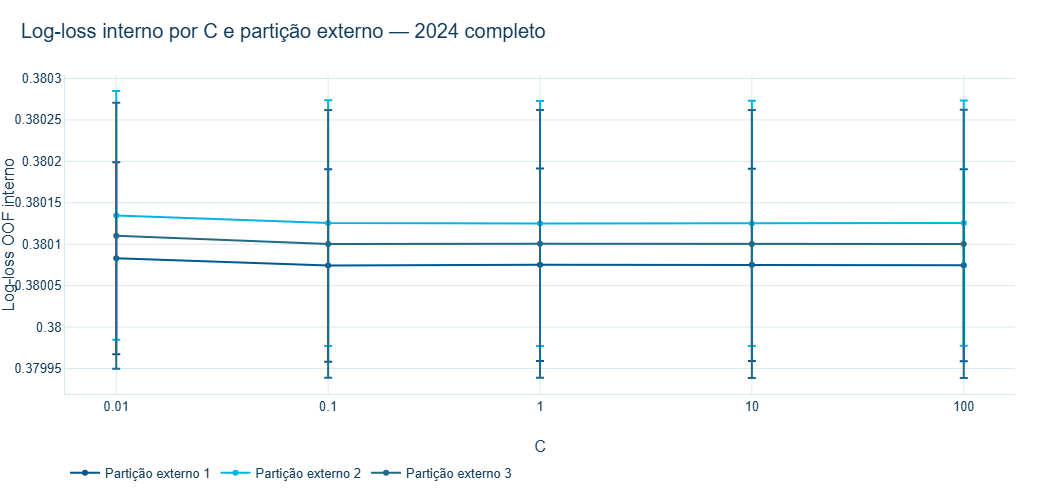

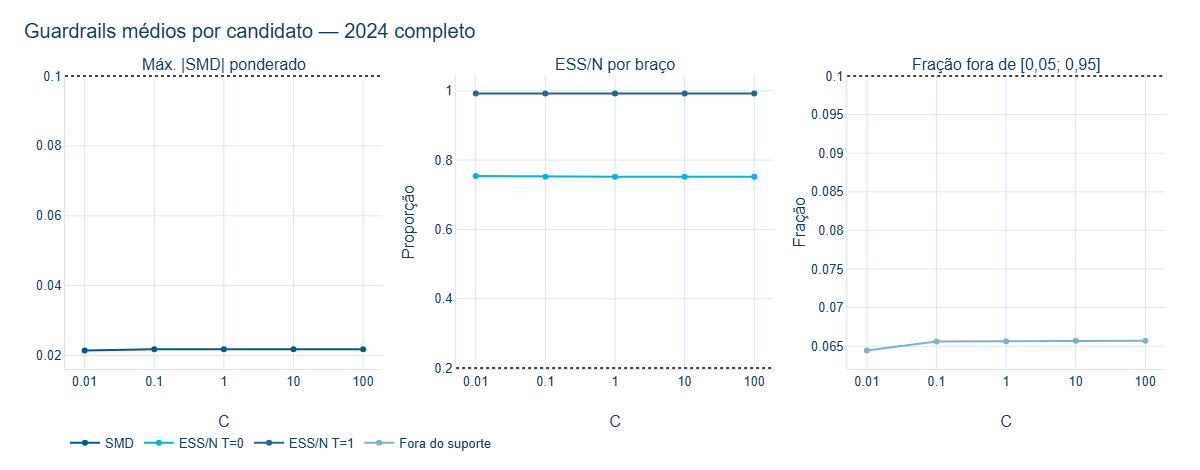

In [6]:
colunas_exibidas = [
    'outer_fold', 'C', 'log_loss', 'log_loss_se_folds', 'brier', 'auc',
    'erro_calibracao_medio', 'max_abs_smd_ponderado', 'ess_t0_sobre_n',
    'ess_t1_sobre_n', 'fora_005_095_fracao', 'dentro_um_ep',
    'passa_guardrails', 'selecionado',
]
display(candidatos[colunas_exibidas].style.format({
    c: '{:.6f}' for c in colunas_exibidas
    if c not in {'outer_fold', 'C', 'dentro_um_ep', 'passa_guardrails', 'selecionado'}
}))

fig_logloss = go.Figure()
for fold, grupo in candidatos.groupby('outer_fold'):
    fig_logloss.add_trace(go.Scatter(
        x=grupo.C, y=grupo.log_loss, error_y=dict(type='data', array=grupo.log_loss_se_folds),
        mode='lines+markers', name=f'Fold externo {fold}',
    ))
fig_logloss.update_xaxes(type='log', title='C', tickvals=list(GRADE_C_PROPENSITY))
fig_logloss.update_yaxes(title='Log-loss OOF interno')
aplicar_tema_ipt(fig_logloss, 'Log-loss interno por C e fold externo — 2024 completo')
fig_logloss.update_layout(width=1050, height=500)
fig_logloss.show()

fig_guardrails = make_subplots(rows=1, cols=3, subplot_titles=[
    'Máx. |SMD| ponderado', 'ESS/N por braço', 'Fração fora de [0,05; 0,95]'
])
media_c = candidatos.groupby('C', as_index=False).mean(numeric_only=True)
fig_guardrails.add_trace(go.Scatter(x=media_c.C, y=media_c.max_abs_smd_ponderado, mode='lines+markers', name='SMD'), row=1, col=1)
fig_guardrails.add_hline(y=0.10, line_dash='dot', line_color='#444444', row=1, col=1)
fig_guardrails.add_trace(go.Scatter(x=media_c.C, y=media_c.ess_t0_sobre_n, mode='lines+markers', name='ESS/N T=0'), row=1, col=2)
fig_guardrails.add_trace(go.Scatter(x=media_c.C, y=media_c.ess_t1_sobre_n, mode='lines+markers', name='ESS/N T=1'), row=1, col=2)
fig_guardrails.add_hline(y=0.20, line_dash='dot', line_color='#444444', row=1, col=2)
fig_guardrails.add_trace(go.Scatter(x=media_c.C, y=media_c.fora_005_095_fracao, mode='lines+markers', name='Fora do suporte'), row=1, col=3)
fig_guardrails.add_hline(y=0.10, line_dash='dot', line_color='#444444', row=1, col=3)
fig_guardrails.update_xaxes(type='log', title='C', tickvals=list(GRADE_C_PROPENSITY))
fig_guardrails.update_yaxes(title='Proporção', row=1, col=2)
fig_guardrails.update_yaxes(title='Fração', row=1, col=3)
aplicar_tema_ipt(fig_guardrails, 'Guardrails médios por candidato — 2024 completo')
fig_guardrails.update_layout(width=1200, height=470)
fig_guardrails.show()

## 10. Resultado OOF externo e decisão

O menor log-loss interno variou entre folds (`0,1`, `1` e `10`), porém `C=1` ficou dentro de 1 EP e passou os guardrails em todos eles. A regra baseline-first escolheu `C=1` em 3/3 folds. O resultado OOF externo global é praticamente idêntico ao cache histórico certificado, com diferenças na sexta casa decimal.

,nested,baseline_C1,diferenca_nested_menos_baseline
log_loss,0.38009633,0.38009481,0.00000152
brier,0.11349133,0.11349045,0.00000089
auc,0.66286708,0.66286228,0.00000480
erro_calibracao_medio,0.00214087,0.00214688,-0.00000601
erro_calibracao_maximo,0.00385086,0.00416025,-0.00030940
max_abs_smd_bruto,0.37521741,0.37521741,0.00000000
max_abs_smd_ponderado,0.02174500,0.02179679,-0.00005180
ess_t0_sobre_n,0.75205347,0.75203050,0.00002296
ess_t1_sobre_n,0.99231741,0.99232138,-0.00000397
fora_005_095_fracao,0.06580431,0.06584339,-0.00003908


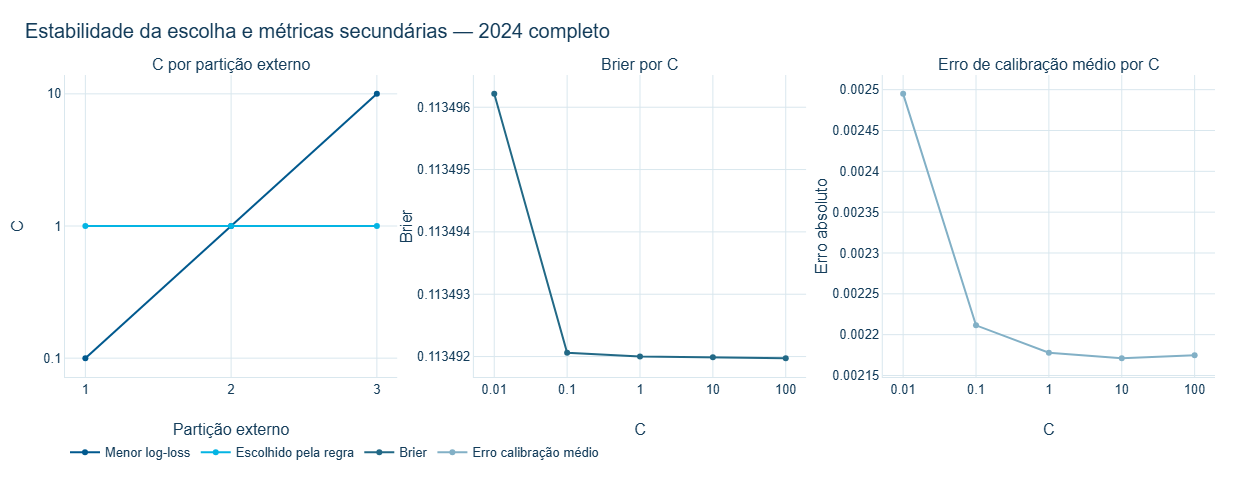

In [7]:
metricas_nested = pd.Series(resumo['metricas_oof_nested'], name='nested')
metricas_baseline = pd.Series(resumo['baseline_c1_certificado'], name='baseline_C1')
comparacao = pd.concat([metricas_nested, metricas_baseline], axis=1)
comparacao['diferenca_nested_menos_baseline'] = comparacao.nested - comparacao.baseline_C1
display(comparacao.loc[[
    'log_loss', 'brier', 'auc', 'erro_calibracao_medio', 'erro_calibracao_maximo',
    'max_abs_smd_bruto', 'max_abs_smd_ponderado', 'ess_t0_sobre_n',
    'ess_t1_sobre_n', 'fora_005_095_fracao', 'propensity_min', 'propensity_max',
]].style.format('{:.8f}'))

fig_escolha = make_subplots(rows=1, cols=3, subplot_titles=[
    'C por fold externo', 'Brier por C', 'Erro de calibração médio por C'
])
rotular_c = lambda serie: serie.map(lambda valor: f'{valor:g}')
fig_escolha.add_trace(go.Scatter(x=folds_resultado.outer_fold, y=rotular_c(folds_resultado.C_menor_log_loss_interno), mode='lines+markers', name='Menor log-loss'), row=1, col=1)
fig_escolha.add_trace(go.Scatter(x=folds_resultado.outer_fold, y=rotular_c(folds_resultado.C_escolhido), mode='lines+markers', name='Escolhido pela regra'), row=1, col=1)
fig_escolha.add_trace(go.Scatter(x=media_c.C, y=media_c.brier, mode='lines+markers', name='Brier'), row=1, col=2)
fig_escolha.add_trace(go.Scatter(x=media_c.C, y=media_c.erro_calibracao_medio, mode='lines+markers', name='Erro calibração médio'), row=1, col=3)
fig_escolha.update_yaxes(type='category', categoryorder='array', categoryarray=['0.01', '0.1', '1', '10', '100'], title='C', row=1, col=1)
fig_escolha.update_xaxes(title='Fold externo', tickmode='array', tickvals=[1, 2, 3], row=1, col=1)
fig_escolha.update_xaxes(type='log', title='C', tickvals=list(GRADE_C_PROPENSITY), row=1, col=2)
fig_escolha.update_xaxes(type='log', title='C', tickvals=list(GRADE_C_PROPENSITY), row=1, col=3)
fig_escolha.update_yaxes(title='Brier', row=1, col=2)
fig_escolha.update_yaxes(title='Erro absoluto', row=1, col=3)
aplicar_tema_ipt(fig_escolha, 'Estabilidade da escolha e métricas secundárias — 2024 completo')
fig_escolha.update_layout(width=1250, height=480)
fig_escolha.show()

assert resumo['decisao_propensity'] == 'BASELINE_C1_PRESERVADO'
assert (folds_resultado.C_escolhido == BASELINE_C).all()

## 11. Custo real e limitações

- SMD ponderado no mesmo OOF usado para avaliar probabilidades é diagnóstico, não prova de ausência de confundimento.
- A grade explora apenas `C`; esta rodada não avaliou HGB nem modelos de outcome.
- Os thresholds são guardrails operacionais, não testes de hipótese.
- O menor log-loss pontual variou entre folds; a estabilidade observada é da **regra final** (`C=1` em 3/3), não do argmin.
- A comparação com o baseline histórico é preditiva e usa partições externas diferentes; diferenças minúsculas não devem ser interpretadas como ganho causal.
- O tempo total foi 712,5 s (11,9 min), 13,6% abaixo da extrapolação linear do piloto.

In [8]:
segundos_piloto = 19.9695537
linhas_fit_piloto = 15 * 80_000
linhas_fit_nested = 45 * 1_000_698 + 3 * 1_501_047
estimativa_linear = segundos_piloto * linhas_fit_nested / linhas_fit_piloto
tempo_real = resumo['auditoria']['tempo_total_segundos']
custo = pd.Series({
    'outer_folds': resumo['auditoria']['n_folds_externos'],
    'inner_folds': resumo['auditoria']['n_folds_internos'],
    'candidatos': resumo['auditoria']['n_candidatos'],
    'refits': resumo['auditoria']['n_refits'],
    'fits_previstos': resumo['auditoria']['total_fits_previstos'],
    'fits_realizados': resumo['auditoria']['total_fits_realizados'],
    'segundos_piloto_120k': segundos_piloto,
    'segundos_estimados_lineares': estimativa_linear,
    'segundos_reais': tempo_real,
    'desvio_real_vs_estimado_pct': 100 * (tempo_real / estimativa_linear - 1),
}, name='custo')
display(custo.to_frame())

,custo
outer_folds,3.000000
inner_folds,3.000000
candidatos,5.000000
refits,3.000000
fits_previstos,48.000000
fits_realizados,48.000000
segundos_piloto_120k,19.969554
segundos_estimados_lineares,824.319063
segundos_reais,712.492501
desvio_real_vs_estimado_pct,-13.565932


## 12. Decisões e próximo passo científico

A execução completa não justifica tuning anual agora: a regra final preservou `C=1` em 3/3 folds e o OOF nested foi praticamente idêntico ao baseline certificado. Antes de multiplicar 48 fits por ano, a prioridade é auditar deriva preditiva e guardrails nos anos já processados.

O tuning de outcome também não é prioritário nesta rodada: nenhum diagnóstico novo de outcome foi produzido, e estabilidade do propensity não constitui evidência de má especificação dos modelos de outcome. Uma decisão futura deve partir de métricas preditivas OOF próprias dos outcomes, separadas de AIPW e CATE.

**Próximo passo científico:** revisão humana destes resultados; depois, auditar deriva temporal de log-loss, calibração, SMD, ESS e caudas com o baseline `C=1` já calculado para 2014–2023, sem executar tuning anual nem qualquer efeito causal. Não criar notebook 09 nesta rodada.

In [9]:
resumo_final = {
    'nested_propensity_2024': resumo['status'],
    'decisao_propensity': resumo['decisao_propensity'],
    'baseline_2024': 'BASELINE_2024_PRESERVADO',
    'tuning_anual': 'TUNING_ANUAL_PROPENSITY_NAO_JUSTIFICADO_AGORA',
    'outcome_tuning': 'OUTCOME_TUNING_NAO_PRIORITARIO',
    'prontidao_outcome': 'PRONTO_PARA_DECIDIR_OUTCOME_TUNING',
    'notebook_09_criado': False,
    'aipw_temporal_executado': False,
    'revisao_humana_obrigatoria': True,
}
display(pd.Series(resumo_final, name='status').to_frame())
assert resumo_final['baseline_2024'] == 'BASELINE_2024_PRESERVADO'
assert resumo_final['decisao_propensity'] == 'BASELINE_C1_PRESERVADO'
assert not resumo_final['notebook_09_criado'] and not resumo_final['aipw_temporal_executado']

,status
nested_propensity_2024,NESTED_PROPENSITY_2024_CONCLUIDO
decisao_propensity,BASELINE_C1_PRESERVADO
baseline_2024,BASELINE_2024_PRESERVADO
tuning_anual,TUNING_ANUAL_PROPENSITY_NAO_JUSTIFICADO_AGORA
outcome_tuning,OUTCOME_TUNING_NAO_PRIORITARIO
prontidao_outcome,PRONTO_PARA_DECIDIR_OUTCOME_TUNING
notebook_09_criado,False
aipw_temporal_executado,False
revisao_humana_obrigatoria,True
